# Pilot simulation: target-level stability under unknown detector gain

**Purpose.** The research statement claims that *the flux of a star can stay well determined even when the detector gain is unknown, while other parts of the image become poorly determined.* This notebook tests that claim on a small simulated problem, and numerically checks the formula in Section B of the statement.

**Model** (same as the statement):

$$y_k = \mathrm{diag}(g)\,A_k x + \varepsilon_k, \qquad g = 1 + B\theta, \qquad \varepsilon_k \sim \mathcal{N}(0, \sigma^2 I)$$

- **Sky** $x = Va$, where $V$ = [constant sky, smooth extended-emission modes, blurred star templates at known positions]. Blur is folded into the star templates.
- **Dithers** $A_k$: each exposure sees an $n \times n$ window of the sky, shifted by a few pixels.
- **Gain** $g$: smooth, zero-mean cosine modes $B$, so the mean gain is fixed to one.
- **Target** $\varphi_j$ = flux of star $j$ = $a_j$. This is a linear functional $w^\top x$ with $w = V(V^\top V)^{-1}e_j$, matching $\varphi = w^\top x$ in the statement.

**Sections**
1. Setup and simulated data
2. Part 1: linearized theory (estimability, κ, variance inflation)
3. Part 2: actual estimation on noisy data (Monte Carlo)
4. Part 3: conformal uncertainty intervals (optional)
5. Robustness across random seeds
6. Writing the pilot sentence, limitations, interview questions

**Requirements:** `numpy`, `pandas`, `matplotlib`. Run all cells top to bottom (Kernel → Restart & Run All). Total runtime is about 1 to 3 minutes.

## 1. Setup

All settings are in the next cell. **Change one at a time** when testing robustness, and note what changes.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator

# ---- configuration ----------------------------------------------------------
N_DET = 32            # detector is N_DET x N_DET pixels
MAX_SHIFT = 4         # largest dither offset in pixels
S = N_DET + MAX_SHIFT # scene grid size
N_STARS = 8
PSF_SIGMA = 1.2       # Gaussian PSF width in pixels
SKY = 100.0           # sky level per pixel
EXT_AMP = 10.0        # amplitude scale of smooth extended emission (keeps total sky positive)
FLUX_RANGE = (500.0, 5000.0)
GAIN_RMS = 0.03       # rms of each gain-mode coefficient
NOISE_SIGMA = 3.0     # Gaussian pixel noise (known)
EXT_ORDER = 3         # extended-emission cosine modes with 1 <= u+v <= EXT_ORDER
GAIN_ORDER = 2        # gain cosine modes with 1 <= u+v <= GAIN_ORDER
DITHER_AMPS = [0, 1, 2, 3, 4]

SEED = 0              # random sky for Parts 1 and 2
MC_TRIALS = 300       # Monte Carlo repetitions in Part 2
MC_AMP = 2            # dither amplitude used in Parts 2 and 3
RUN_CONFORMAL = True  # Part 3 takes about a minute
N_CASES = 1000        # independent cases in Part 3

BLUE, ORANGE = "#2a78d6", "#eb6834"

### Building blocks
- `cosine_modes`: smooth 2-D patterns used for both extended emission (on the sky) and gain (on the detector).
- `Problem`: one simulated case. It holds the basis $V$, the gain modes $B$, the dither offsets, and the true parameters, and it provides the forward model and the noise-whitened Jacobian $J = [J_a \; J_\theta]$.

In [12]:
def cosine_modes(size, max_order):
    # 2-D cosine modes, 1 <= u+v <= max_order; zero mean on the grid, unit rms
    idx = (np.arange(size) + 0.5) / size
    modes = []
    for u in range(max_order + 1):
        for v in range(max_order + 1):
            if 1 <= u + v <= max_order:
                m = np.outer(np.cos(np.pi * u * idx), np.cos(np.pi * v * idx))
                modes.append((m / np.sqrt(np.mean(m ** 2))).ravel())
    return np.array(modes).T

def star_templates(positions):
    # unit-flux Gaussian PSF templates on the scene grid
    yy, xx = np.mgrid[0:S, 0:S]
    cols = []
    for (py, px) in positions:
        t = np.exp(-((yy - py) ** 2 + (xx - px) ** 2) / (2 * PSF_SIGMA ** 2))
        cols.append((t / t.sum()).ravel())
    return np.array(cols).T

def random_positions(rng):
    # stars placed where every dither window sees them, with a minimum separation
    lo, hi = MAX_SHIFT + 3, N_DET - 3
    pos = []
    while len(pos) < N_STARS:
        p = rng.uniform(lo, hi, size=2)
        if all(np.hypot(*(p - q)) > 4 * PSF_SIGMA for q in pos):
            pos.append(p)
    return np.array(pos)

def dither_offsets(amp):
    # four exposures on a square pattern of side `amp` pixels
    return [(0, 0), (amp, 0), (0, amp), (amp, amp)]

def window(img_flat, off):
    # A_k: extract the detector window at offset (dy, dx)
    dy, dx = off
    return img_flat.reshape(S, S)[dy:dy + N_DET, dx:dx + N_DET].ravel()

class Problem:
    def __init__(self, rng, amp):
        self.pos = random_positions(rng)
        ext = cosine_modes(S, EXT_ORDER)
        self.V = np.hstack([np.ones((S * S, 1)), ext, star_templates(self.pos)])
        self.n_ext = ext.shape[1]
        self.ext_idx = np.arange(1, 1 + self.n_ext)
        self.star_idx = np.arange(1 + self.n_ext, self.V.shape[1])
        self.B = cosine_modes(N_DET, GAIN_ORDER)
        self.offs = dither_offsets(amp)
        self.AV = [np.array([window(self.V[:, j], o) for j in range(self.V.shape[1])]).T
                   for o in self.offs]
        self.a_true = np.concatenate([[SKY], EXT_AMP * rng.standard_normal(self.n_ext),
                                      rng.uniform(*FLUX_RANGE, size=N_STARS)])
        self.th_true = GAIN_RMS * rng.standard_normal(self.B.shape[1])

    def gain(self, th):
        return 1.0 + self.B @ th

    def predict(self, a, th):
        g = self.gain(th)
        return np.concatenate([g * (AV @ a) for AV in self.AV])

    def jacobian(self, a, th):
        g = self.gain(th)
        Ja = np.vstack([g[:, None] * AV for AV in self.AV])
        Jt = np.vstack([(AV @ a)[:, None] * self.B for AV in self.AV])
        return Ja / NOISE_SIGMA, Jt / NOISE_SIGMA

    def simulate(self, rng):
        y0 = self.predict(self.a_true, self.th_true)
        return y0 + NOISE_SIGMA * rng.standard_normal(y0.size)

### Look at the simulated data
Left to right: the true sky (with stars circled), the extended emission alone, the true gain pattern, and one noisy exposure. Notice that the extended emission and the gain are both smooth. That is why they can be confused, while sharp stars cannot.

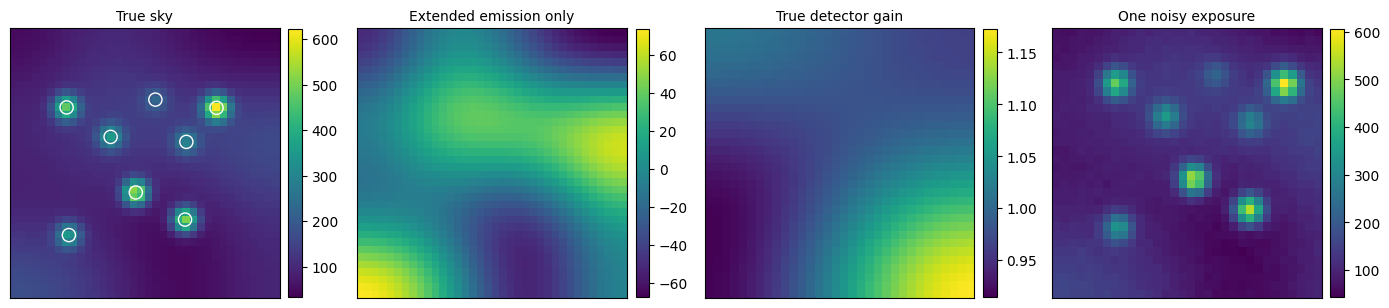

Minimum sky value: 32.2 (should be positive)
Gain range: 0.914 to 1.173  |  star fluxes: [2021, 2262, 4506, 1522, 3304, 878, 4247, 4042]


In [13]:
rng = np.random.default_rng(SEED)
demo = Problem(rng, MC_AMP)
sky = (demo.V @ demo.a_true).reshape(S, S)
ext_only = (demo.V[:, demo.ext_idx] @ demo.a_true[demo.ext_idx]).reshape(S, S)
g_true = demo.gain(demo.th_true).reshape(N_DET, N_DET)
y_demo = demo.simulate(rng)[:N_DET * N_DET].reshape(N_DET, N_DET)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))
panels = [(sky, "True sky"), (ext_only, "Extended emission only"),
          (g_true, "True detector gain"), (y_demo, "One noisy exposure")]
for ax, (img, title) in zip(axs, panels):
    im = ax.imshow(img, origin="lower", cmap="viridis")
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
axs[0].scatter(demo.pos[:, 1], demo.pos[:, 0], s=90, facecolors="none", edgecolors="white", lw=1)
plt.tight_layout(); plt.show()
print(f"Minimum sky value: {sky.min():.1f} (should be positive)")
print(f"Gain range: {g_true.min():.3f} to {g_true.max():.3f}  |  star fluxes: "
      f"{np.round(demo.a_true[demo.star_idx]).astype(int).tolist()}")

## 2. Part 1: Linearized theory at the true parameters

For each target (each star flux, and each extended-emission coefficient) we compute:

- **Estimability:** the target vector $a = (e_j, 0)$ must lie in the row space of $J$ (equivalently, $a \perp \ker J$).
- **κ with known gain**, $\kappa_{\text{known}}^2 = e_j^\top (J_a^\top J_a)^{-1} e_j$.
- **κ with unknown gain**, $\kappa_\varphi^2 = \|(J^\dagger)^\top a\|_2^2$, computed two ways: by direct inversion, and by the Schur-complement formula in the statement,
$$\kappa_\varphi^2 = \kappa_{\text{known}}^2 + \sum_i \frac{(e_j^\top M v_i)^2}{s_i^2}, \qquad M = (J_a^\top J_a)^{-1}J_a^\top J_\theta,$$
where $s_i, v_i$ are the singular values and right singular vectors of $C = (I - P_a)J_\theta$.
- **Variance inflation** $= \kappa_\varphi^2 / \kappa_{\text{known}}^2$: how much the unknown gain costs. **1.0 means no penalty.**
- **Worst image direction:** the largest inflation over *every* linear combination of image coefficients, i.e. the least stable thing one could try to measure.

In [14]:
def kappa_analysis(prob, a, th):
    Ja, Jt = prob.jacobian(a, th)
    J = np.hstack([Ja, Jt])
    p = Ja.shape[1]
    Fa = Ja.T @ Ja
    Sig_known = np.linalg.inv(Fa)
    Sig_joint = np.linalg.pinv(J.T @ J)[:p, :p]
    M = np.linalg.solve(Fa, Ja.T @ Jt)
    C = Jt - Ja @ M                                   # (I - P_a) J_theta
    _, s, Vt = np.linalg.svd(C, full_matrices=False)
    rank = np.linalg.matrix_rank(J)
    P_row = np.linalg.pinv(J) @ J                     # projector onto row space of J

    rows = []
    I = np.eye(p)
    labels = [(i, f"star {k}") for k, i in enumerate(prob.star_idx)] + \
             [(i, f"ext mode {k}") for k, i in enumerate(prob.ext_idx)]
    for idx, label in labels:
        e = I[idx]
        avec = np.concatenate([e, np.zeros(Jt.shape[1])])
        estimable = np.linalg.norm(avec - P_row @ avec) < 1e-8 * np.linalg.norm(avec)
        k2_known = e @ Sig_known @ e
        k2_joint = e @ Sig_joint @ e
        calib = np.sum(((e @ M) @ Vt.T) ** 2 / s ** 2) if rank == J.shape[1] else np.nan
        rows.append({"target": label, "estimable": estimable,
                     "kappa_known": np.sqrt(k2_known), "kappa_joint": np.sqrt(k2_joint),
                     "formula_rel_err": abs(np.sqrt(k2_known + calib) - np.sqrt(k2_joint)) / np.sqrt(k2_joint),
                     "inflation": k2_joint / k2_known})
    w, U = np.linalg.eigh(Sig_known)
    Sk_mhalf = U @ np.diag(w ** -0.5) @ U.T
    worst = np.linalg.eigvalsh(Sk_mhalf @ Sig_joint @ Sk_mhalf).max()
    return pd.DataFrame(rows), {"rank": rank, "n_params": J.shape[1],
                                "s_min_C": s.min(), "worst_inflation": worst}

Run the analysis for each dither amplitude, on the **same** simulated sky.

In [15]:
summary = []
for amp in DITHER_AMPS:
    prob = Problem(np.random.default_rng(SEED), amp)
    df, info = kappa_analysis(prob, prob.a_true, prob.th_true)
    stars = df[df.target.str.startswith("star")]
    ext = df[df.target.str.startswith("ext")]
    summary.append({"dither amp (px)": amp,
                    "rank / params": f"{info['rank']}/{info['n_params']}",
                    "all stars estimable": bool(stars.estimable.all()),
                    "s_min(C)": info["s_min_C"],
                    "star inflation (median)": stars.inflation.median(),
                    "star inflation (max)": stars.inflation.max(),
                    "ext inflation (median)": ext.inflation.median(),
                    "worst direction inflation": info["worst_inflation"],
                    "max formula rel. error": df.formula_rel_err.max()})
part1 = pd.DataFrame(summary)
display(part1.round({"s_min(C)": 1, "star inflation (median)": 2, "star inflation (max)": 2,
                     "ext inflation (median)": 2, "worst direction inflation": 1}))

,dither amp (px),rank / params,all stars estimable,s_min(C),star inflation (median),star inflation (max),ext inflation (median),worst direction inflation,max formula rel. error
0,0,23/23,True,264.7,4.61,16.75,11.17,101.9,1.184886e-11
1,1,23/23,True,307.8,3.54,11.32,9.53,72.3,1.854024e-11
2,2,23/23,True,405.6,2.62,6.88,6.40,41.0,4.533452e-12
3,3,23/23,True,527.7,2.07,4.49,4.33,24.4,1.168187e-11
4,4,23/23,True,661.7,1.75,3.18,3.09,16.2,4.891972e-12


**How to read this table**
- `max formula rel. error` should be tiny (about 1e-10 or smaller). This confirms the formula in the statement.
- Compare `star inflation` with `worst direction inflation`. **The claim is supported if star-flux inflation is much smaller.**
- Both should fall as the dither amplitude grows, because larger dithers separate gain (fixed to the detector) from emission (fixed to the sky).

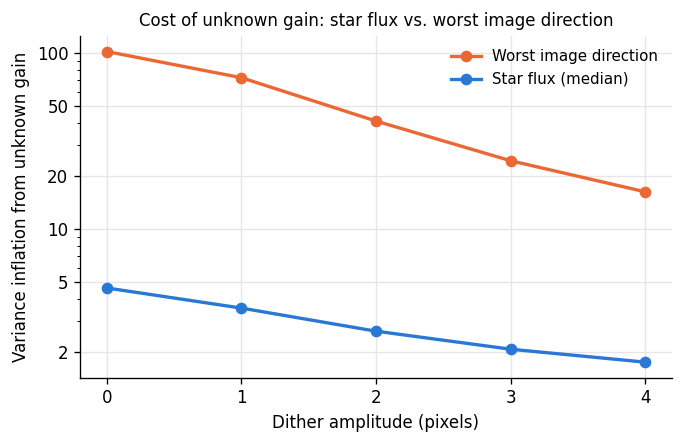

In [16]:
fig, ax = plt.subplots(figsize=(5.8, 3.8), dpi=120)
ax.plot(part1["dither amp (px)"], part1["worst direction inflation"], color=ORANGE, lw=2,
        marker="o", ms=6, label="Worst image direction")
ax.plot(part1["dither amp (px)"], part1["star inflation (median)"], color=BLUE, lw=2,
        marker="o", ms=6, label="Star flux (median)")
ax.set_yscale("log")
ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax.set_xticks(DITHER_AMPS)
ax.set_xlabel("Dither amplitude (pixels)")
ax.set_ylabel("Variance inflation from unknown gain")
ax.set_title("Cost of unknown gain: star flux vs. worst image direction", fontsize=10)
ax.grid(True, color="#e6e6e6", lw=0.8)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
fig.savefig("inflation_vs_dither.png", dpi=200)
plt.show()

Per-target detail at the Monte Carlo dither amplitude:

In [17]:
prob = Problem(np.random.default_rng(SEED), MC_AMP)
detail, info = kappa_analysis(prob, prob.a_true, prob.th_true)
print(info)
display(detail.round({"kappa_known": 2, "kappa_joint": 2, "inflation": 2}))

{'rank': np.int64(23), 'n_params': 23, 's_min_C': np.float64(405.5784725365004), 'worst_inflation': np.float64(41.01395873145778)}


,target,estimable,kappa_known,kappa_joint,formula_rel_err,inflation
0,star 0,True,7.02,9.48,6.001921e-13,1.82
1,star 1,True,7.16,11.00,1.908804e-12,2.36
2,star 2,True,6.99,18.34,1.299680e-13,6.88
3,star 3,True,6.91,7.99,5.115895e-15,1.33
4,star 4,True,6.87,16.79,1.610501e-12,5.96
5,star 5,True,6.99,7.85,5.993458e-13,1.26
6,star 6,True,6.78,11.49,9.590957e-13,2.87
7,star 7,True,6.39,12.46,1.617101e-12,3.79
8,ext mode 0,True,0.06,0.23,4.002425e-12,17.24
9,ext mode 1,True,0.05,0.15,2.656096e-12,7.65


## 3. Part 2: Actual estimation on noisy data

Part 1 is a local, linearized prediction. Here we check it against reality:

- **Joint estimator:** Gauss–Newton on $(a, \theta)$, starting from a flat gain.
- **Nominal-gain estimator:** naive least squares that assumes $g = 1$. This shows why calibration matters.

| Column | Meaning |
|---|---|
| `joint rel. RMSE %` | Typical flux error of the joint estimator, as a percent of the true flux |
| `joint bias %` | Average flux error; should be near zero |
| `nominal-gain bias %` | Average error when the gain is wrongly assumed flat |
| `pred/emp sd` | Predicted scatter (κ) divided by observed scatter; **near 1.0 means the theory predicts reality** |

In [18]:
def estimate_joint(prob, y, iters=30):
    th = np.zeros(prob.B.shape[1])
    a = np.linalg.lstsq(np.vstack(prob.AV), y, rcond=None)[0]
    for _ in range(iters):
        r = (y - prob.predict(a, th)) / NOISE_SIGMA
        Ja, Jt = prob.jacobian(a, th)
        step = np.linalg.lstsq(np.hstack([Ja, Jt]), r, rcond=None)[0]
        a, th = a + step[:a.size], th + step[a.size:]
        if np.linalg.norm(step) < 1e-10 * (1 + np.linalg.norm(a)):
            break
    return a, th

def estimate_nominal(prob, y):
    return np.linalg.lstsq(np.vstack(prob.AV), y, rcond=None)[0]

def monte_carlo(seed, amp, trials):
    rng = np.random.default_rng(seed)
    prob = Problem(rng, amp)
    df, _ = kappa_analysis(prob, prob.a_true, prob.th_true)
    kap = df[df.target.str.startswith("star")].kappa_joint.values
    ej, en, ee = [], [], []
    for _ in range(trials):
        y = prob.simulate(rng)
        a_j, _ = estimate_joint(prob, y)
        a_n = estimate_nominal(prob, y)
        ej.append(a_j[prob.star_idx] - prob.a_true[prob.star_idx])
        en.append(a_n[prob.star_idx] - prob.a_true[prob.star_idx])
        ee.append(a_j[prob.ext_idx] - prob.a_true[prob.ext_idx])
    ej, en, ee = map(np.array, (ej, en, ee))
    flux = prob.a_true[prob.star_idx]
    stars = pd.DataFrame({"flux": flux,
                          "joint rel. RMSE %": 100 * np.sqrt((ej ** 2).mean(0)) / flux,
                          "joint bias %": 100 * ej.mean(0) / flux,
                          "nominal-gain bias %": 100 * en.mean(0) / flux,
                          "pred/emp sd": kap / ej.std(0)})
    ext_rmse = 100 * np.sqrt((ee ** 2).mean(0)) / np.abs(prob.a_true[prob.ext_idx])
    return stars, ext_rmse

part2, ext_rmse = monte_carlo(SEED, MC_AMP, MC_TRIALS)
print(f"Dither amplitude {MC_AMP}, {MC_TRIALS} trials")
print(f"Extended-emission coefficients, joint rel. RMSE %: median {np.median(ext_rmse):.2f}, max {ext_rmse.max():.2f}")
display(part2.round({"flux": 0, "joint rel. RMSE %": 3, "joint bias %": 3,
                     "nominal-gain bias %": 2, "pred/emp sd": 3}))

Dither amplitude 2, 300 trials
Extended-emission coefficients, joint rel. RMSE %: median 1.08, max 16.60


,flux,joint rel. RMSE %,joint bias %,nominal-gain bias %,pred/emp sd
0,2021.0,0.474,0.010,-3.52,0.990
1,2262.0,0.499,-0.003,-6.23,0.974
2,4506.0,0.429,-0.016,-2.52,0.949
3,1522.0,0.543,0.017,-0.31,0.967
4,3304.0,0.501,-0.008,-1.29,1.014
5,878.0,0.942,0.067,-0.99,0.951
6,4247.0,0.276,-0.007,-0.89,0.979
7,4042.0,0.298,0.022,6.43,1.036


**Sanity check:** every `pred/emp sd` should be close to 1. With 300 trials, values within about ±0.1 of 1 are consistent with sampling noise.

## 4. Part 3 (optional): Conformal uncertainty intervals

Many independent simulated cases, each with a new sky, gain and noise. Half calibrate, half test. Scores are $|\hat\varphi - \varphi| / \hat\kappa$, with κ computed **at the estimate**, since the truth is unknown in practice.

- **Per-star intervals:** calibrated on one randomly chosen star per case, so calibration scores are independent across cases.
- **Simultaneous intervals:** calibrated on the case-level maximum score, so all stars in a field are covered at once.
- **Coverage by brightness:** checks whether faint stars are covered as well as bright ones.

With 500 calibration cases, coverage fluctuates by roughly ±0.015 around 0.95. That is expected.

In [19]:
def conformal(seed, amp, n_cases, alpha=0.05):
    rng = np.random.default_rng(seed + 1)
    rows = []
    for _ in range(n_cases):
        prob = Problem(rng, amp)
        y = prob.simulate(rng)
        a_hat, th_hat = estimate_joint(prob, y)
        df, _ = kappa_analysis(prob, a_hat, th_hat)        # kappa at the estimate
        kap = df[df.target.str.startswith("star")].kappa_joint.values
        err = np.abs(a_hat[prob.star_idx] - prob.a_true[prob.star_idx])
        rows.append((err / kap, prob.a_true[prob.star_idx]))
    half = n_cases // 2
    cal, test = rows[:half], rows[half:]

    def qhat(scores):
        n = len(scores); k = int(np.ceil((n + 1) * (1 - alpha)))
        return np.sort(scores)[min(k, n) - 1]

    q_marg = qhat(np.array([r[0][rng.integers(N_STARS)] for r in cal]))
    q_sim = qhat(np.array([r[0].max() for r in cal]))
    ts = np.concatenate([r[0] for r in test]); tf = np.concatenate([r[1] for r in test])
    cover = ts <= q_marg
    cover_sim = np.array([r[0].max() <= q_sim for r in test])
    edges = np.quantile(tf, [0, 1/3, 2/3, 1])
    by_bin = pd.DataFrame([{"flux bin": f"{lo:.0f} to {hi:.0f}",
                            "per-star coverage": cover[(tf >= lo) & (tf <= hi)].mean()}
                           for lo, hi in zip(edges[:-1], edges[1:])])
    overall = pd.DataFrame([{"interval type": "per star", "half-width (x kappa)": q_marg, "coverage": cover.mean()},
                            {"interval type": "simultaneous (whole field)", "half-width (x kappa)": q_sim, "coverage": cover_sim.mean()}])
    return overall, by_bin

if RUN_CONFORMAL:
    overall, by_bin = conformal(SEED, MC_AMP, N_CASES)
    display(overall.round(3))
    display(by_bin.round(3))

,interval type,half-width (x kappa),coverage
0,per star,1.985,0.954
1,simultaneous (whole field),2.700,0.944


,flux bin,per-star coverage
0,500 to 1993,0.954
1,1993 to 3457,0.951
2,3457 to 4998,0.957


## 5. Robustness across random seeds

A single random sky can be lucky. This cell repeats the key numbers for five seeds, with fewer Monte Carlo trials to keep it fast. **Report what is typical, not the best seed.**

In [20]:
rob = []
for seed in range(5):
    prob = Problem(np.random.default_rng(seed), MC_AMP)
    df, info = kappa_analysis(prob, prob.a_true, prob.th_true)
    st = df[df.target.str.startswith("star")]
    mc, _ = monte_carlo(seed, MC_AMP, 100)
    rob.append({"seed": seed,
                "star inflation (median)": st.inflation.median(),
                "worst direction inflation": info["worst_inflation"],
                "ratio worst / star": info["worst_inflation"] / st.inflation.median(),
                "joint rel. RMSE % (max)": mc["joint rel. RMSE %"].max(),
                "nominal-gain |bias| % (max)": mc["nominal-gain bias %"].abs().max(),
                "pred/emp sd (min)": mc["pred/emp sd"].min(),
                "pred/emp sd (max)": mc["pred/emp sd"].max()})
robust = pd.DataFrame(rob)
display(robust.round(2))
print("Median across seeds:")
print(robust.drop(columns="seed").median().round(2).to_string())

,seed,star inflation (median),worst direction inflation,ratio worst / star,joint rel. RMSE % (max),nominal-gain |bias| % (max),pred/emp sd (min),pred/emp sd (max)
0,0,2.62,41.01,15.67,0.92,6.41,0.96,1.14
1,1,2.44,38.88,15.94,1.10,6.64,0.86,1.14
2,2,4.00,49.03,12.25,0.45,8.35,1.00,1.19
3,3,2.51,51.10,20.35,0.61,7.77,0.89,1.11
4,4,2.59,44.39,17.13,0.65,7.80,0.87,1.08


Median across seeds:
star inflation (median)         2.59
worst direction inflation      44.39
ratio worst / star             15.94
joint rel. RMSE % (max)         0.65
nominal-gain |bias| % (max)     7.77
pred/emp sd (min)               0.89
pred/emp sd (max)               1.14


## 6. Writing the pilot sentence

Use **your own numbers** from Sections 2 to 5, and describe what you actually observe. Two templates:

> In pilot simulations of a 32 × 32 detector with eight stars and smooth extended emission, unknown gain inflated star-flux variance by a median factor of **[A]**, compared with **[B]** for the least stable image direction, and the predicted scatter matched Monte Carlo estimates to within **[C]%**.

> In pilot simulations, joint calibration reduced star-flux bias from up to **[D]%** under an assumed flat gain to below **[E]%**, and the stability measure predicted the observed scatter to within **[C]%**.

**Be honest about what the pilot shows.** If star-flux inflation is clearly above 1, do not write "no penalty." Write that the penalty for stars is much smaller than for the least stable image direction. That is the claim this pilot supports.

### Sanity checklist before using any number
1. `max formula rel. error` is tiny (Part 1).
2. `pred/emp sd` is close to 1 for every star (Part 2).
3. The pattern holds across seeds (Section 5).
4. Changing one configuration setting at a time (for example `NOISE_SIGMA`, `GAIN_RMS` or `EXT_AMP`) moves the results in the direction you expect.

### Limitations (be ready to state these)
- Gaussian noise with known variance; Poisson noise is not yet included.
- Star positions and the point-spread function are known (forced photometry).
- Integer-pixel dithers, a small detector, and smooth gain only (no pixel-level gain component η).
- Part 1 is a local, linearized analysis at the true parameters.
- No learned prior yet; this tests the identifiability theory in Section B, not Section C.

### Questions you may be asked in an interview
- Why does star flux stay stable while extended emission does not? *(Hint: a smooth gain change looks like smooth emission, but not like a sharp point source.)*
- Why are all parameters identifiable even at zero dither amplitude? *(Hint: stars at different detector positions sample the gain pattern. Check `s_min(C)`.)*
- What would change with Poisson noise, or with pixel-level gain variations?
- Why compute κ at the estimate in Part 3 rather than at the truth?
- Why is the case, not the star, the unit of independence for conformal calibration?